# Next-Day AQI Prediction for Indian Cities Using Machine Learning

**Student:** Maanyaa Desai  
**Roll No.:** 2427010218  
**Course:** B.Tech CSE (AI & ML), Manipal University Jaipur



## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)

## 2. Load the dataset
.

In [2]:
# For Jupyter Notebook running on your computer:
df = pd.read_csv("city_day.csv")

# For Google Colab instead, comment the line above and use:
# from google.colab import files
# uploaded = files.upload()
# df = pd.read_csv("city_day.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 3. Understand and inspect the data

In [3]:
print("Columns:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

print("\\nStatistical summary:")
display(df.describe(include="all").T)

Columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-nu

,Missing values
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854


\nStatistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
City,29531,26,Ahmedabad,2009,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,29531,2009,2020-03-11,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM2.5,24933.0,NaN,NaN,NaN,67.450578,64.661449,0.04,28.82,48.57,80.59,949.99
PM10,18391.0,NaN,NaN,NaN,118.127103,90.60511,0.01,56.255,95.68,149.745,1000.0
NO,25949.0,NaN,NaN,NaN,17.57473,22.785846,0.02,5.63,9.89,19.95,390.68
NO2,25946.0,NaN,NaN,NaN,28.560659,24.474746,0.01,11.75,21.69,37.62,362.21
NOx,25346.0,NaN,NaN,NaN,32.309123,31.646011,0.0,12.82,23.52,40.1275,467.63
NH3,19203.0,NaN,NaN,NaN,23.483476,25.684275,0.01,8.58,15.85,30.02,352.89
CO,27472.0,NaN,NaN,NaN,2.248598,6.962884,0.0,0.51,0.89,1.45,175.81
SO2,25677.0,NaN,NaN,NaN,14.531977,18.133775,0.01,5.67,9.16,15.22,193.86


## 4. Data cleaning and exploratory data analysis

In [4]:
# Convert Date to datetime and sort observations
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["City", "Date", "AQI"]).copy()
df = df.sort_values(["City", "Date"]).reset_index(drop=True)

print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Number of cities:", df["City"].nunique())
print("Rows after removing missing target/date/city:", len(df))

Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00
Number of cities: 26
Rows after removing missing target/date/city: 24850


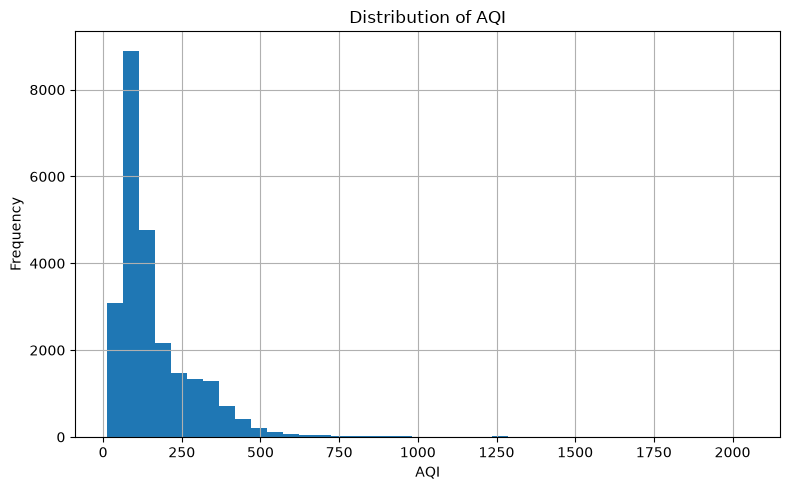

In [5]:
# Distribution of AQI
plt.figure(figsize=(8, 5))
df["AQI"].hist(bins=40)
plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

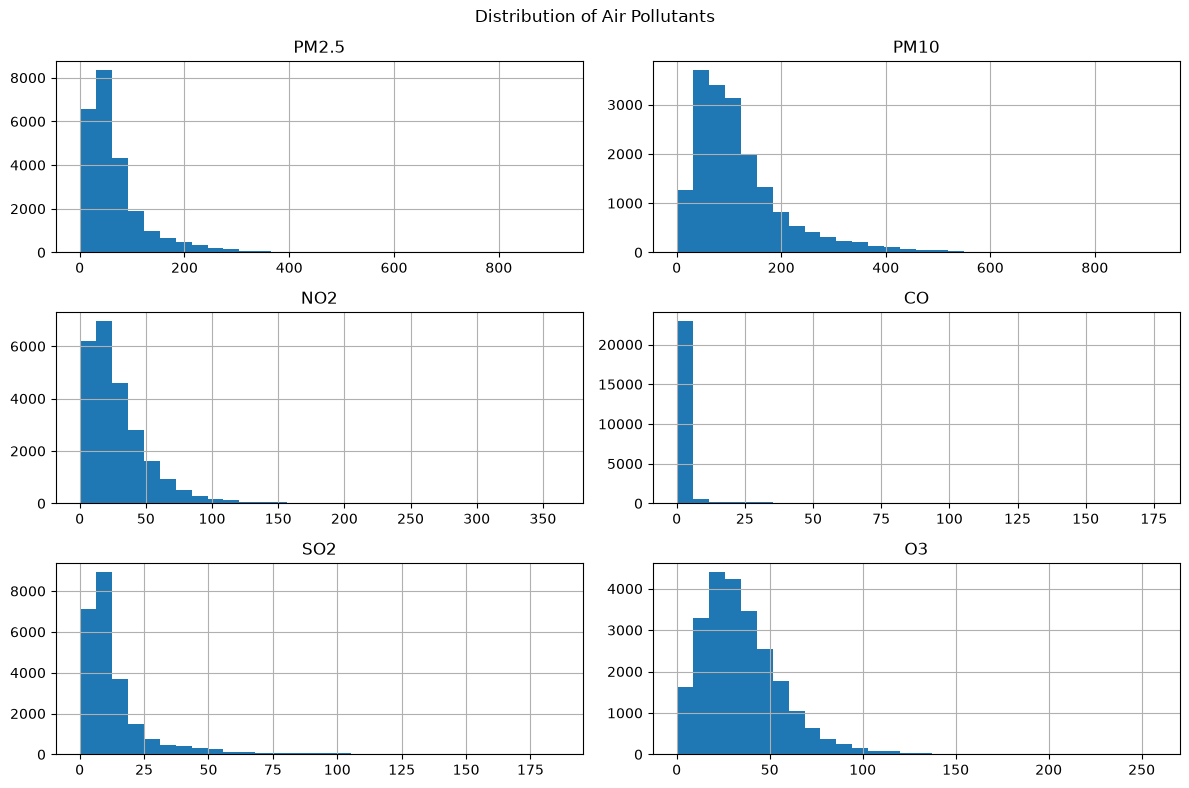

In [6]:
# Distribution of selected pollutants
pollutants = [c for c in ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3"] if c in df.columns]

df[pollutants].hist(figsize=(12, 8), bins=30)
plt.suptitle("Distribution of Air Pollutants")
plt.tight_layout()
plt.show()

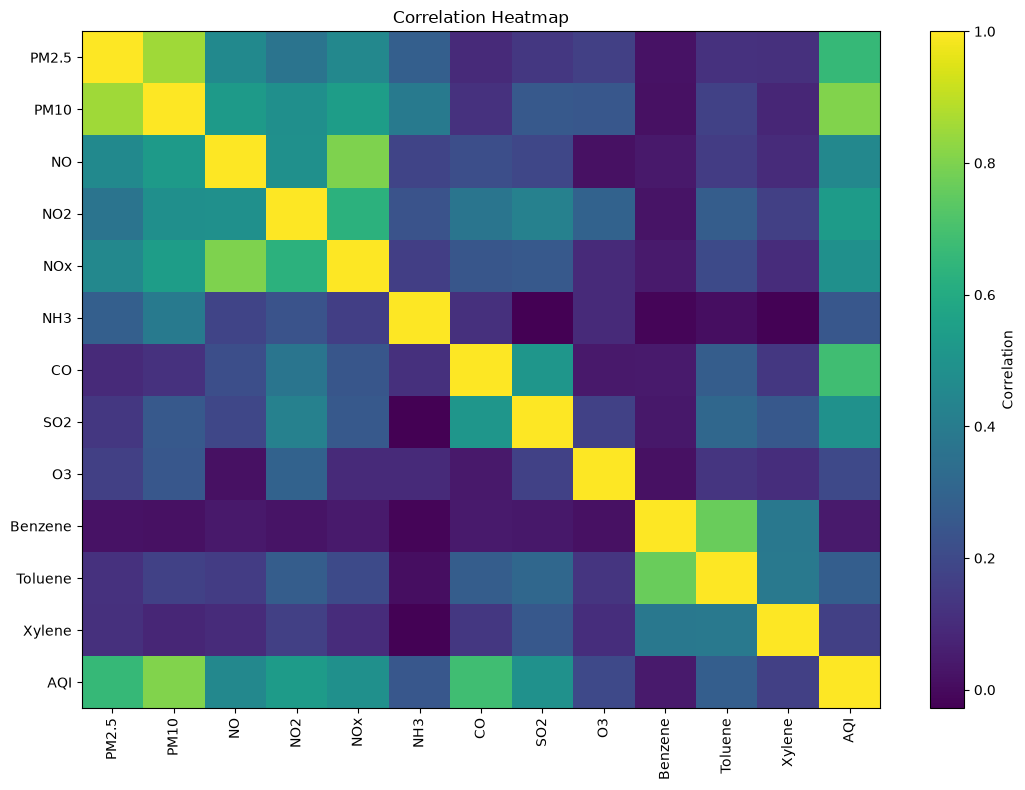

In [7]:
# Correlation heatmap for numerical columns
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(11, 8))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

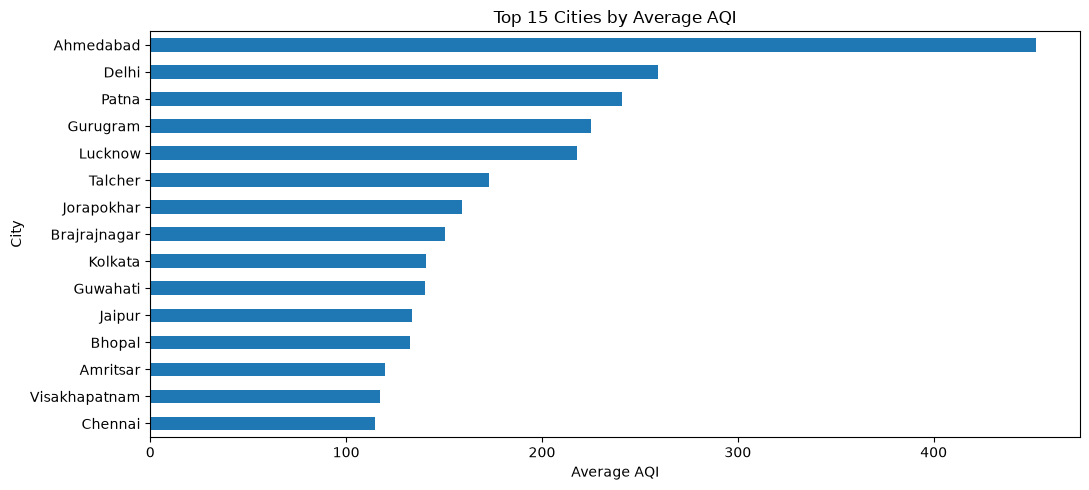

In [8]:
# Average AQI by city (top 15 cities)
city_aqi = df.groupby("City")["AQI"].mean().sort_values(ascending=False).head(15)

plt.figure(figsize=(11, 5))
city_aqi.sort_values().plot(kind="barh")
plt.title("Top 15 Cities by Average AQI")
plt.xlabel("Average AQI")
plt.tight_layout()
plt.show()

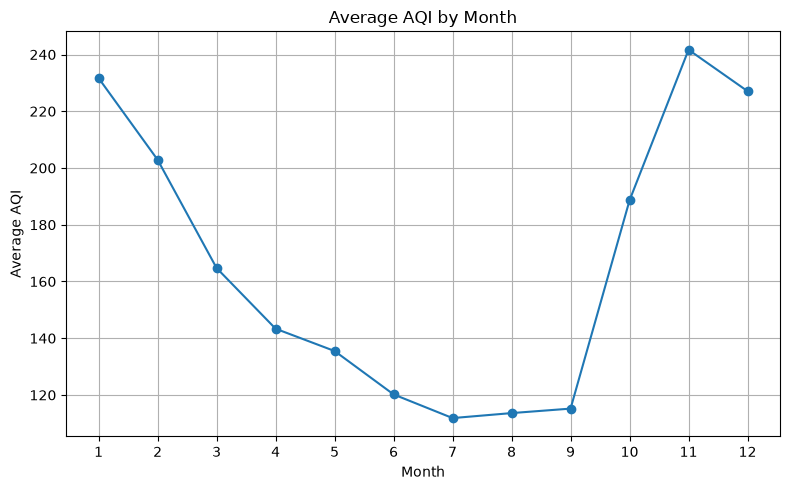

In [9]:
# Average AQI by month
monthly_aqi = df.groupby(df["Date"].dt.month)["AQI"].mean()

plt.figure(figsize=(8, 5))
monthly_aqi.plot(marker="o")
plt.title("Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

## 5. Create next-day prediction features
For each city, the target is the AQI on the next calendar day. The input features use the previous day's AQI and pollutant readings. Rows are retained only when the previous and target dates are consecutive.

In [10]:
# Keep the original daily record as the target-day row
data = df.copy()
data["Target_AQI"] = data.groupby("City")["AQI"].shift(-1)
data["Target_Date"] = data.groupby("City")["Date"].shift(-1)

# Create previous-day lag features
lag_columns = ["AQI"] + pollutants
for col in lag_columns:
    data[f"Previous_{col}"] = data.groupby("City")[col].shift(0)

# Move the target to the next date, while current row represents the previous day
# The model inputs are values on date t and target AQI is on date t+1.
data["Date_Gap"] = (data["Target_Date"] - data["Date"]).dt.days
data = data[data["Date_Gap"] == 1].copy()

# Date features known for the target day
data["Month"] = data["Target_Date"].dt.month
data["DayOfWeek"] = data["Target_Date"].dt.dayofweek

print("Usable next-day samples:", len(data))
display(data[["City", "Date", "Target_Date", "AQI", "Target_AQI"]].head())

Usable next-day samples: 24343


,City,Date,Target_Date,AQI,Target_AQI
0,Ahmedabad,2015-01-29,2015-01-30,209.0,328.0
1,Ahmedabad,2015-01-30,2015-01-31,328.0,514.0
2,Ahmedabad,2015-01-31,2015-02-01,514.0,782.0
3,Ahmedabad,2015-02-01,2015-02-02,782.0,914.0
4,Ahmedabad,2015-02-02,2015-02-03,914.0,660.0


**Important interpretation:** Each row uses the air-quality readings from a given date to predict the AQI on the following calendar day. The `AQI_Bucket` column is not used because it is derived from AQI and could cause target leakage.

## 6. Prepare features and chronological train-test split

In [11]:
# Features: city, previous-day AQI/pollutants, and target-date calendar features
feature_columns = ["City"] + [f"Previous_{c}" for c in lag_columns] + ["Month", "DayOfWeek"]

X = data[feature_columns].copy()
y = data["Target_AQI"].copy()

# Chronological 80:20 split by target date (no random shuffling)
data = data.sort_values("Target_Date").reset_index(drop=True)
X = data[feature_columns]
y = data["Target_AQI"]

split_index = int(len(data) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training target dates:", data["Target_Date"].iloc[0], "to", data["Target_Date"].iloc[split_index-1])
print("Testing target dates:", data["Target_Date"].iloc[split_index], "to", data["Target_Date"].iloc[-1])

Training rows: 19474
Testing rows: 4869
Training target dates: 2015-01-02 00:00:00 to 2019-12-08 00:00:00
Testing target dates: 2019-12-08 00:00:00 to 2020-07-01 00:00:00


## 7. Preprocessing and model training
Missing numerical values are filled using the median. Missing city values are filled using the most frequent value, and city names are one-hot encoded.

In [12]:
numeric_features = [c for c in feature_columns if c != "City"]

try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    # Compatibility with older scikit-learn versions
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, ["City"])
    ]
)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(results_df.round(3))

,Model,MAE,RMSE,R2
0,Random Forest,18.226,34.868,0.850
1,Gradient Boosting,19.682,36.604,0.835
2,Linear Regression,22.140,37.923,0.823
3,Decision Tree,28.344,54.054,0.640


## 8. Compare model performance

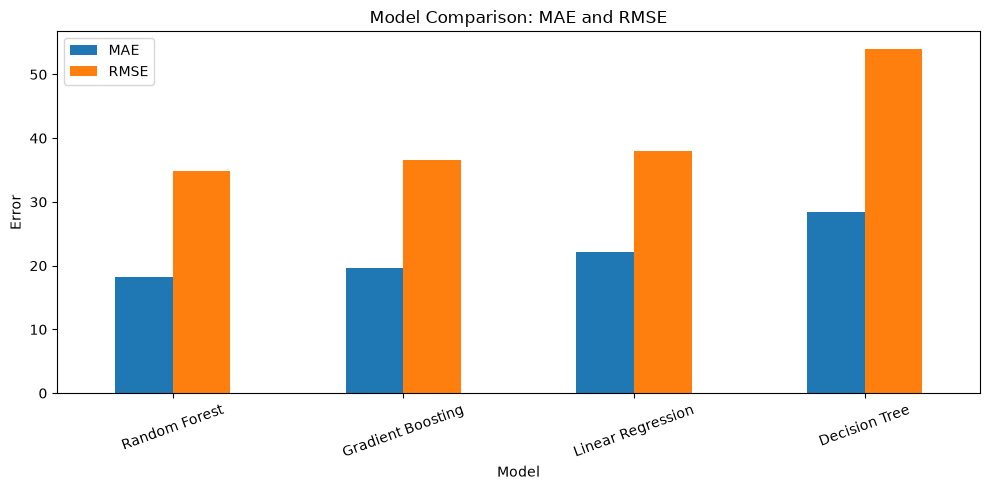

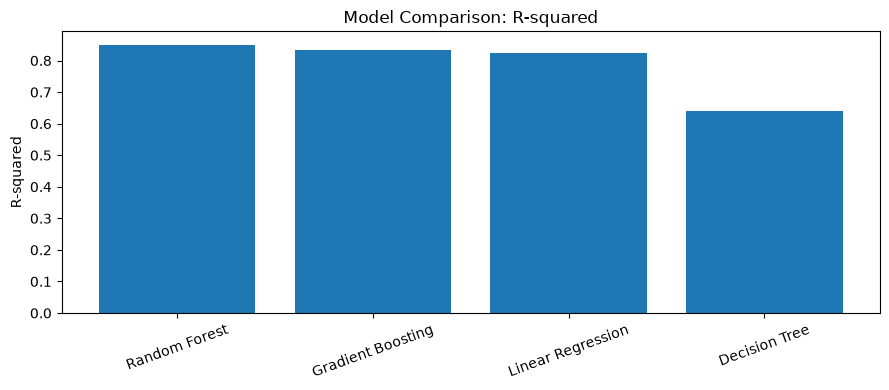

In [13]:
# MAE and RMSE comparison
plot_results = results_df.set_index("Model")[["MAE", "RMSE"]]
plot_results.plot(kind="bar", figsize=(10, 5))
plt.title("Model Comparison: MAE and RMSE")
plt.ylabel("Error")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# R-squared comparison
plt.figure(figsize=(9, 4))
plt.bar(results_df["Model"], results_df["R2"])
plt.title("Model Comparison: R-squared")
plt.ylabel("R-squared")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 9. Actual vs predicted AQI for the best-MAE model

Best model by MAE: Random Forest


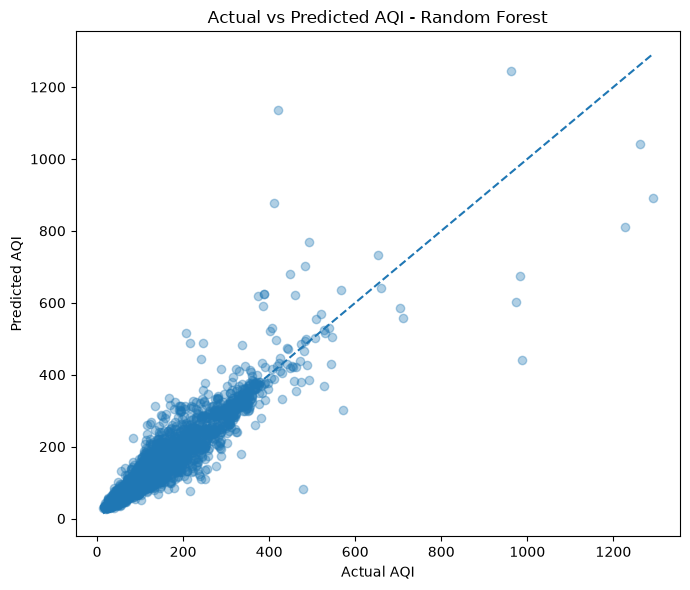

In [14]:
best_model_name = results_df.loc[results_df["MAE"].idxmin(), "Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Best model by MAE:", best_model_name)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.35)
min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title(f"Actual vs Predicted AQI - {best_model_name}")
plt.tight_layout()
plt.show()

## 10. Feature importance (tree-based best-MAE model, if applicable)

,Feature,Importance
0,num__Previous_AQI,0.653179
4,num__Previous_CO,0.197926
1,num__Previous_PM2.5,0.054412
6,num__Previous_O3,0.019245
3,num__Previous_NO2,0.019054
5,num__Previous_SO2,0.016825
2,num__Previous_PM10,0.014257
7,num__Month,0.009659
8,num__DayOfWeek,0.006049
9,cat__City_Ahmedabad,0.002669


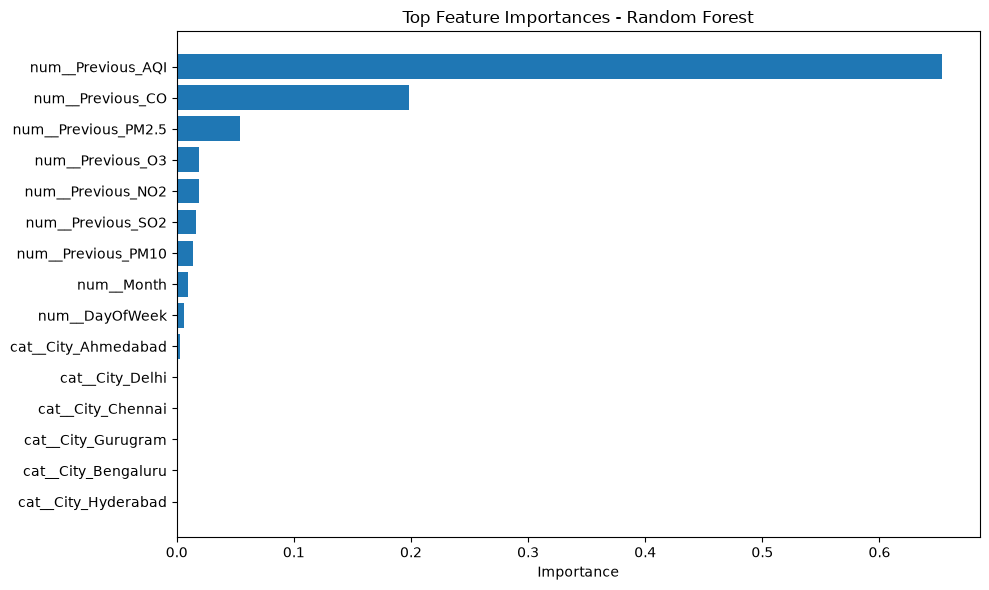

In [15]:
if best_model_name in ["Decision Tree", "Random Forest", "Gradient Boosting"]:
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_estimator = best_model.named_steps["model"]

    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_estimator.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(15)

    display(importance_df)

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df["Feature"][::-1], importance_df["Importance"][::-1])
    plt.title(f"Top Feature Importances - {best_model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("The selected best-MAE model is not tree-based, so built-in feature importance is not available.")

## 11. Generate a next-day AQI estimate for the latest city observation
This uses the latest available record for each city and predicts one day after that record. It is a model estimate, not an official AQI reading.

In [16]:
latest_rows = df.sort_values("Date").groupby("City").tail(1).copy()
latest_rows["Month"] = (latest_rows["Date"] + pd.Timedelta(days=1)).dt.month
latest_rows["DayOfWeek"] = (latest_rows["Date"] + pd.Timedelta(days=1)).dt.dayofweek

forecast_X = pd.DataFrame(index=latest_rows.index)
forecast_X["City"] = latest_rows["City"]

for col in lag_columns:
    forecast_X[f"Previous_{col}"] = latest_rows[col]

forecast_X["Month"] = latest_rows["Month"]
forecast_X["DayOfWeek"] = latest_rows["DayOfWeek"]
forecast_X = forecast_X[feature_columns]

latest_model = trained_models[best_model_name]
latest_rows["Predicted_Next_Day_AQI"] = latest_model.predict(forecast_X)
latest_rows["Forecast_Date"] = latest_rows["Date"] + pd.Timedelta(days=1)

forecast_table = latest_rows[["City", "Date", "Forecast_Date", "Predicted_Next_Day_AQI"]]
forecast_table = forecast_table.sort_values("Predicted_Next_Day_AQI", ascending=False)
display(forecast_table.head(10))

,City,Date,Forecast_Date,Predicted_Next_Day_AQI
12444,Gurugram,2020-07-01,2020-07-02,149.01
1333,Ahmedabad,2020-07-01,2020-07-02,128.47
10838,Delhi,2020-07-01,2020-07-02,127.89
15913,Jaipur,2020-07-01,2020-07-02,120.50
3411,Amritsar,2020-07-01,2020-07-02,119.44
16684,Jorapokhar,2020-07-01,2020-07-02,115.82
21723,Patna,2020-07-01,2020-07-02,94.23
16842,Kochi,2020-07-01,2020-07-02,88.40
22626,Talcher,2020-07-01,2020-07-02,87.94
6312,Brajrajnagar,2020-06-12,2020-06-13,87.16


## 12. Save model results and forecast tables

In [17]:
results_df.to_csv("aqi_model_comparison.csv", index=False)
forecast_table.to_csv("next_day_aqi_forecasts.csv", index=False)

print("Saved: aqi_model_comparison.csv")
print("Saved: next_day_aqi_forecasts.csv")

Saved: aqi_model_comparison.csv
Saved: next_day_aqi_forecasts.csv


## 13. Conclusion

- The notebook compared Linear Regression, Decision Tree, Random Forest, and Gradient Boosting.
- MAE, RMSE, and R-squared were used to evaluate the models.
- The model with the lowest MAE was selected for the actual-versus-predicted plot.
- The final table provides next-day AQI estimates for the latest available record of each city.

**Note:** Results can differ slightly if the dataset version, library versions, or model settings differ from those used to prepare the written report.